# 02 – Tiền xử lý dữ liệu và xây dựng đặc trưng RFM

**Mục tiêu notebook:**
1. Làm sạch dữ liệu giao dịch theo các quyết định rút ra từ `01_EDA.ipynb`.
2. Tổng hợp dữ liệu về cấp khách hàng và tính các đặc trưng **RFM** (Recency, Frequency, Monetary) cùng các đặc trưng mở rộng.
3. Phân tích ngoại lệ ở cấp khách hàng, biến đổi phân phối và chuẩn hóa để chuẩn bị đầu vào cho các thuật toán phân cụm.
4. Xây dựng **baseline chấm điểm RFM theo quy tắc** (không dùng học máy) để so sánh với các thuật toán phân cụm ở các notebook sau.

**Đầu ra:** các file trong `outputs/` gồm `clean_transactions.parquet`, `rfm_features.csv`, `rfm_model_input.csv`, `rfm_ext_input.csv`, `rfm_scores.csv`, `cleaning_log.csv`.

## 1. Đọc dữ liệu

In [1]:
import sys, warnings
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.decomposition import PCA

from src.data_utils import load_raw, clean_transactions, build_rfm, outlier_report, rfm_scores
from src import viz
viz.setup()
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
OUT = Path("../outputs"); OUT.mkdir(exist_ok=True)

raw = load_raw()
print("Dữ liệu gốc:", raw.shape)

Dữ liệu gốc: (541910, 8)


## 2. Làm sạch dữ liệu giao dịch
Pipeline được cài đặt trong hàm `clean_transactions()` (file `src/data_utils.py`), gồm 5 bước theo thứ tự:

| Bước | Thao tác | Lý do (từ EDA) |
|---|---|---|
| 1 | Loại dòng trùng lặp hoàn toàn | Lỗi ghi nhận hai lần |
| 2 | Loại dòng thiếu Customer ID | Không gán được giao dịch cho khách hàng nào |
| 3 | Tách hóa đơn hủy (Invoice bắt đầu "C") ra bảng `returns` | Không phải hành vi mua, nhưng dùng để tính Monetary ròng |
| 4 | Loại Quantity ≤ 0 hoặc Price ≤ 0 | Hàng tặng, điều chỉnh nợ xấu |
| 5 | Loại mã không phải sản phẩm (POST, DOT, M, BANK CHARGES, AMAZONFEE, gift voucher…) | Phí dịch vụ, không phải giá trị hàng hóa |

Sau đó tạo thuộc tính mới `TotalPrice = Quantity × Price`.

In [2]:
sales, returns, clog = clean_transactions(raw)
clog.to_csv(OUT / "cleaning_log.csv", index=False)
print(f"\nBảng returns (dòng hủy của khách có ID): {len(returns):,} dòng, tổng giá trị {returns['TotalPrice'].sum():,.2f} £")

                                         Bước  Số dòng còn lại  Số dòng bị loại  % còn lại so với gốc
                               0. Dữ liệu gốc           541910                0                100.00
             1. Loại dòng trùng lặp hoàn toàn           536642             5268                 99.03
               2. Loại dòng thiếu Customer ID           401605           135037                 74.11
         3. Tách hóa đơn hủy (Invoice 'C...')           392733             8872                 72.47
        4. Loại Quantity <= 0 hoặc Price <= 0           392693               40                 72.46
5. Loại mã không phải sản phẩm (POST, M, ...)           391150             1543                 72.18

Bảng returns (dòng hủy của khách có ID): 8,506 dòng, tổng giá trị -471,750.71 £


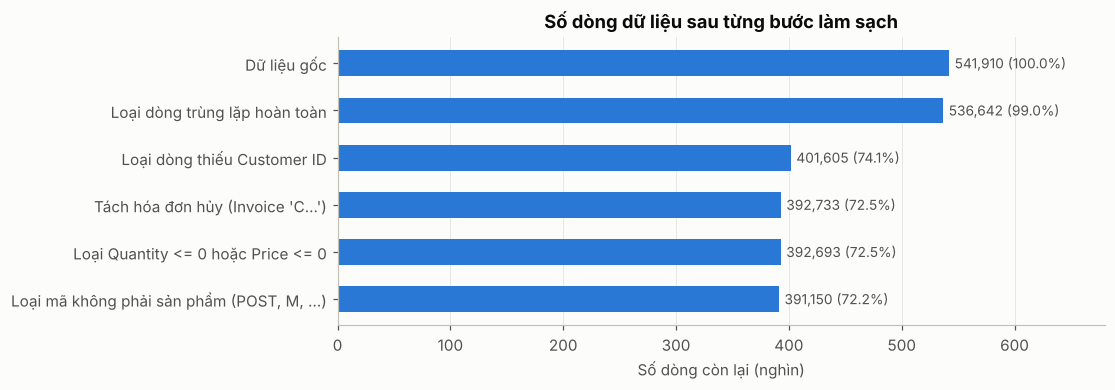

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.4))
labels = [s.split(". ", 1)[1] for s in clog["Bước"]]
ax.barh(labels[::-1], clog["Số dòng còn lại"][::-1] / 1e3, color=viz.MAIN, height=.55)
for i, (v, p) in enumerate(zip(clog["Số dòng còn lại"][::-1], clog["% còn lại so với gốc"][::-1])):
    ax.text(v / 1e3 + 5, i, f"{v:,} ({p:.1f}%)", va="center", color=viz.INK2, fontsize=9)
ax.set_xlim(0, 680); ax.set_xlabel("Số dòng còn lại (nghìn)"); ax.grid(axis="y", visible=False)
ax.set_title("Số dòng dữ liệu sau từng bước làm sạch")
viz.save(fig, "fig09_cleaning_funnel"); plt.show()

In [4]:
# Kiểm tra lại chất lượng dữ liệu sau làm sạch
checks = {
    "Không còn giá trị thiếu": sales.isna().sum().sum() == 0,
    "Không còn dòng trùng": sales.duplicated().sum() == 0,
    "Quantity > 0": (sales["Quantity"] > 0).all(),
    "Price > 0": (sales["Price"] > 0).all(),
    "Không còn hóa đơn hủy": (~sales["Invoice"].str.startswith("C")).all(),
}
display(pd.Series(checks, name="Đạt").to_frame())
print(f"Sau làm sạch: {len(sales):,} dòng | {sales['Invoice'].nunique():,} hóa đơn | "
      f"{sales['Customer ID'].nunique():,} khách hàng | {sales['StockCode'].nunique():,} sản phẩm | "
      f"{sales['Country'].nunique()} quốc gia")
sales[["Quantity", "Price", "TotalPrice"]].describe().T

,Đạt
Không còn giá trị thiếu,True
Không còn dòng trùng,True
Quantity > 0,True
Price > 0,True
Không còn hóa đơn hủy,True


Sau làm sạch: 391,150 dòng | 18,402 hóa đơn | 4,334 khách hàng | 3,659 sản phẩm | 37 quốc gia


,count,mean,std,min,25%,50%,75%,max
Quantity,"391,150.00",13.15,180.81,1.00,2.00,6.00,12.00,"80,995.00"
Price,"391,150.00",2.87,4.28,0.04,1.25,1.95,3.75,649.50
TotalPrice,"391,150.00",22.34,310.93,0.06,4.95,11.90,19.80,"168,469.60"


**Nhận xét:**
- Từ 541.910 dòng ban đầu còn lại **391.150 dòng (72,2%)**, gồm 18.402 hóa đơn, 4.334 khách hàng, 3.659 sản phẩm và 37 quốc gia. Bước làm mất nhiều dữ liệu nhất là **loại dòng thiếu Customer ID** (135.037 dòng). Đây là điều bắt buộc với bài toán phân khúc khách hàng.
- Bảng `returns` giữ lại 8.506 dòng hủy của khách có mã, tổng giá trị khoảng **−471.751 £**. Giá trị này sẽ được trừ vào Monetary.
- Sau làm sạch, Price đã hợp lý (max 649,5 £). Quantity vẫn còn giá trị cực lớn (80.995) vì đơn hàng tương ứng chỉ bị trừ ngược khi tính Monetary ròng ở cấp khách hàng.
- Tất cả các kiểm tra chất lượng (không thiếu, không trùng, Quantity và Price dương, không còn hóa đơn hủy) đều đạt.

## 3. Xây dựng đặc trưng RFM cấp khách hàng

**Định nghĩa** (ngày tham chiếu – snapshot – là ngày sau giao dịch cuối cùng):

| Đặc trưng | Công thức | Ý nghĩa |
|---|---|---|
| **Recency (R)** | snapshot − ngày mua gần nhất (ngày) | Càng nhỏ thì khách càng mới quay lại |
| **Frequency (F)** | Số hóa đơn mua khác nhau | Mức độ thường xuyên |
| **Monetary (M)** | Σ TotalPrice mua − Σ giá trị trả lại (£) | Giá trị ròng mang lại |
| Tenure (T) | snapshot − ngày mua đầu tiên (ngày) | "Tuổi" của khách hàng |
| AOV | Monetary / Frequency | Giá trị trung bình mỗi đơn hàng |
| NumProducts | Số mã sản phẩm khác nhau đã mua | Độ đa dạng giỏ hàng |
| ReturnRate | Giá trị trả lại / giá trị mua | Xu hướng trả hàng |

Bộ **RFM** (3 chiều) là đầu vào chính của các thuật toán phân cụm. Bộ **RFM mở rộng** (RFM + T, AOV, NumProducts, ReturnRate) được dùng để thử nghiệm bổ sung và để mô tả hồ sơ các cụm.

In [5]:
rfm_all, snapshot = build_rfm(sales, returns)
print("Ngày tham chiếu (snapshot):", snapshot.date())
print("Số khách hàng:", len(rfm_all))
rfm_all.head()

Ngày tham chiếu (snapshot): 2011-12-10
Số khách hàng: 4334


,Recency,Frequency,Monetary,Tenure,AOV,NumProducts,ReturnRate,GrossMonetary,ReturnedValue,Country
Customer ID,,,,,,,,,,
12346,325,1,0.00,325,0.00,1,1.00,"77,183.60","77,183.60",United Kingdom
12347,2,7,"4,310.00",367,615.71,103,0.00,"4,310.00",0.00,Iceland
12348,75,4,"1,437.24",358,359.31,21,0.00,"1,437.24",0.00,Finland
12349,18,1,"1,457.55",18,"1,457.55",72,0.00,"1,457.55",0.00,Italy
12350,310,1,294.40,310,294.40,16,0.00,294.40,0.00,Norway


In [6]:
bad = rfm_all[rfm_all["Monetary"] <= 0]
print(f"Khách có Monetary ròng <= 0 (trả lại toàn bộ hoặc nhiều hơn giá trị mua trong kỳ): {len(bad)}")
display(bad[["Recency", "Frequency", "GrossMonetary", "ReturnedValue", "Monetary"]].sort_values("GrossMonetary", ascending=False).head(6))
rfm = rfm_all[rfm_all["Monetary"] > 0].copy()
print("Số khách hàng giữ lại để phân khúc:", len(rfm))

Khách có Monetary ròng <= 0 (trả lại toàn bộ hoặc nhiều hơn giá trị mua trong kỳ): 14


,Recency,Frequency,GrossMonetary,ReturnedValue,Monetary
Customer ID,,,,,
12346,325,1,"77,183.60","77,183.60",0.00
12454,56,1,"3,528.34","3,528.34",0.00
12607,60,1,"1,579.51","1,579.51",0.00
14557,85,1,788.38,788.38,0.00
16546,290,2,787.15,883.08,-95.93
13762,218,1,306.72,306.72,0.00


Số khách hàng giữ lại để phân khúc: 4320


In [7]:
FEAT = ["Recency", "Frequency", "Monetary", "Tenure", "AOV", "NumProducts", "ReturnRate"]
rfm[FEAT].describe(percentiles=[.25, .5, .75, .9, .99]).T

,count,mean,std,min,25%,50%,75%,90%,99%,max
Recency,"4,320.00",92.07,100.12,0.00,17.00,50.00,142.00,263.00,368.00,373.00
Frequency,"4,320.00",4.26,7.65,1.00,1.00,2.00,5.00,9.00,30.00,206.00
Monetary,"4,320.00","1,914.27","8,303.78",2.90,299.05,650.42,"1,610.46","3,451.85","17,061.55","278,778.02"
Tenure,"4,320.00",223.08,117.76,0.00,113.00,249.00,326.00,366.00,373.00,373.00
AOV,"4,320.00",369.43,464.80,1.45,173.47,281.67,419.84,640.46,"1,939.06","13,206.50"
NumProducts,"4,320.00",61.58,85.39,1.00,16.00,35.00,77.25,143.00,353.81,"1,785.00"
ReturnRate,"4,320.00",0.02,0.06,0.00,0.00,0.00,0.01,0.04,0.30,1.00


**Nhận xét:**
- Ngày tham chiếu là **10/12/2011**. Có 4.334 khách hàng, trong đó **14 khách có Monetary ròng ≤ 0**: họ đã trả lại toàn bộ giá trị đã mua trong kỳ. Ví dụ điển hình là khách 12346 với đơn 77.183,6 £ bị hủy hoàn toàn. Những khách này không tạo ra giá trị nên được loại, còn lại **4.320 khách hàng**.
- Khách 16446 (đơn 80.995 sản phẩm bị hủy) giờ chỉ còn Monetary = 2,9 £, đúng với giá trị thật. Điều này chứng minh cách tính Monetary ròng là cần thiết.
- **Khách hàng điển hình** (trung vị): lần mua cuối cách đây 50 ngày, có 2 hóa đơn, chi 650 £, khoảng 282 £/đơn và 35 sản phẩm khác nhau.
- Mọi đặc trưng (trừ Tenure) đều có trung bình lớn hơn nhiều so với trung vị, tức là phân phối lệch phải.

## 4. Phân tích ngoại lệ ở cấp khách hàng

,Thuộc tính,Q1,Q3,Cận dưới,Cận trên,Số ngoại lệ,% ngoại lệ,Skewness
0,Recency,17.00,142.00,-170.50,329.50,153,3.54,1.25
1,Frequency,1.00,5.00,-5.00,11.00,278,6.44,11.94
2,Monetary,299.05,"1,610.46","-1,668.07","3,577.58",410,9.49,21.54
3,Tenure,113.00,326.00,-206.50,645.50,0,0.00,-0.37
4,AOV,173.47,419.84,-196.08,789.39,275,6.37,10.66
5,NumProducts,16.00,77.25,-75.88,169.12,305,7.06,6.91
6,ReturnRate,0.00,0.01,-0.01,0.02,660,15.28,7.52


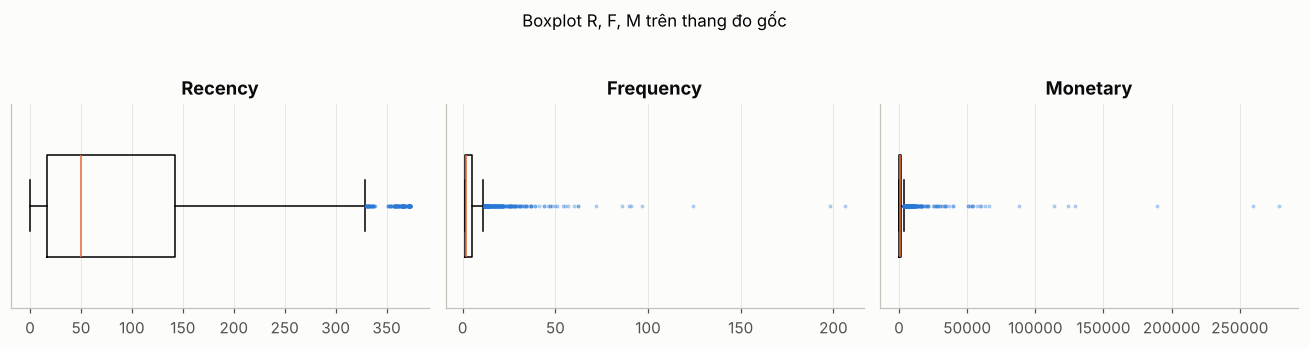

In [8]:
orep = outlier_report(rfm, FEAT)
display(orep)

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, c in zip(axes, ["Recency", "Frequency", "Monetary"]):
    ax.boxplot(rfm[c], vert=False, widths=.5, flierprops=dict(marker=".", markersize=3, alpha=.4, markeredgecolor=viz.MAIN),
               medianprops=dict(color=viz.ACCENT))
    ax.set_title(c); ax.set_yticks([])
fig.suptitle("Boxplot R, F, M trên thang đo gốc", y=1.04, fontsize=11)
fig.tight_layout(); viz.save(fig, "fig10_rfm_boxplots"); plt.show()

In [9]:
# Ai là các khách hàng ngoại lệ? (Top 8 theo Monetary)
rfm.sort_values("Monetary", ascending=False).head(8)[["Recency", "Frequency", "Monetary", "AOV", "NumProducts", "Country"]]

,Recency,Frequency,Monetary,AOV,NumProducts,Country
Customer ID,,,,,,
14646,1,72,"278,778.02","3,871.92",699,Netherlands
18102,0,60,"259,657.30","4,327.62",150,United Kingdom
17450,8,46,"189,575.53","4,121.21",124,United Kingdom
14911,1,198,"128,768.24",650.34,1785,EIRE
12415,24,20,"123,638.18","6,181.91",443,Australia
14156,9,54,"113,685.77","2,105.29",713,EIRE
17511,2,31,"88,138.20","2,843.17",453,United Kingdom
16684,4,28,"65,920.12","2,354.29",119,United Kingdom


In [10]:
# Ảnh hưởng của top 1% khách hàng
top1 = rfm["Monetary"] >= rfm["Monetary"].quantile(.99)
print(f"Top 1% khách hàng ({top1.sum()} khách) chiếm {100 * rfm.loc[top1, 'Monetary'].sum() / rfm['Monetary'].sum():.1f}% tổng Monetary")

Top 1% khách hàng (44 khách) chiếm 30.4% tổng Monetary


**Nhận xét:**
- Theo quy tắc IQR, tỉ lệ ngoại lệ là Recency 3,5%, Frequency 6,4% và Monetary 9,5%. ReturnRate có tới 15,3% vì 65% khách có giá trị bằng 0, khiến IQR gần như bằng 0.
- Các khách "ngoại lệ" lớn nhất là **khách bán buôn/doanh nghiệp thật** (14646 – Netherlands: 278.778 £ và 72 đơn; 18102 – UK: 259.657 £). **Top 1% khách hàng (44 khách) chiếm 30,4% tổng Monetary.**
- → **Quyết định: không loại bỏ ngoại lệ.** Lý do: (1) đây là giá trị thật chứ không phải lỗi; (2) đây là nhóm quan trọng nhất về mặt kinh doanh; (3) loại bỏ sẽ làm sai lệch kết quả phân khúc. Thay vào đó, nhóm giảm ảnh hưởng của chúng bằng biến đổi log (mục 5), và việc so sánh độ nhạy với ngoại lệ giữa các thuật toán (K-Means so với HDBSCAN) sẽ là một nội dung đánh giá.

## 5. Biến đổi phân phối
Các thuật toán dựa trên khoảng cách (K-Means, Hierarchical-Ward) và GMM (giả định phân phối chuẩn trong mỗi cụm) đều nhạy với phân phối lệch và ngoại lệ. Nhóm so sánh ba lựa chọn:
- **Không biến đổi** (dữ liệu gốc)
- **log1p**: $x' = \ln(1 + x)$, đơn giản, dễ diễn giải và đảo ngược
- **Yeo-Johnson** (`PowerTransformer`): tự ước lượng tham số λ để phân phối gần chuẩn nhất

Tiêu chí so sánh là độ lệch (skewness) sau biến đổi: càng gần 0 thì phân phối càng cân đối.

In [11]:
CORE = ["Recency", "Frequency", "Monetary"]
EXT = ["Recency", "Frequency", "Monetary", "Tenure", "AOV", "NumProducts", "ReturnRate"]
pt = PowerTransformer(method="yeo-johnson", standardize=False)
yj = pd.DataFrame(pt.fit_transform(rfm[EXT]), columns=EXT, index=rfm.index)
skew_tab = pd.DataFrame({
    "Gốc": rfm[EXT].skew(),
    "log1p": np.log1p(rfm[EXT]).skew(),
    "Yeo-Johnson": yj.skew(),
}).round(2)
skew_tab

,Gốc,log1p,Yeo-Johnson
Recency,1.25,-0.46,-0.06
Frequency,11.94,1.21,0.22
Monetary,21.54,0.37,-0.01
Tenure,-0.37,-1.60,-0.42
AOV,10.66,0.02,-0.00
NumProducts,6.91,-0.24,-0.00
ReturnRate,7.52,6.21,1.36


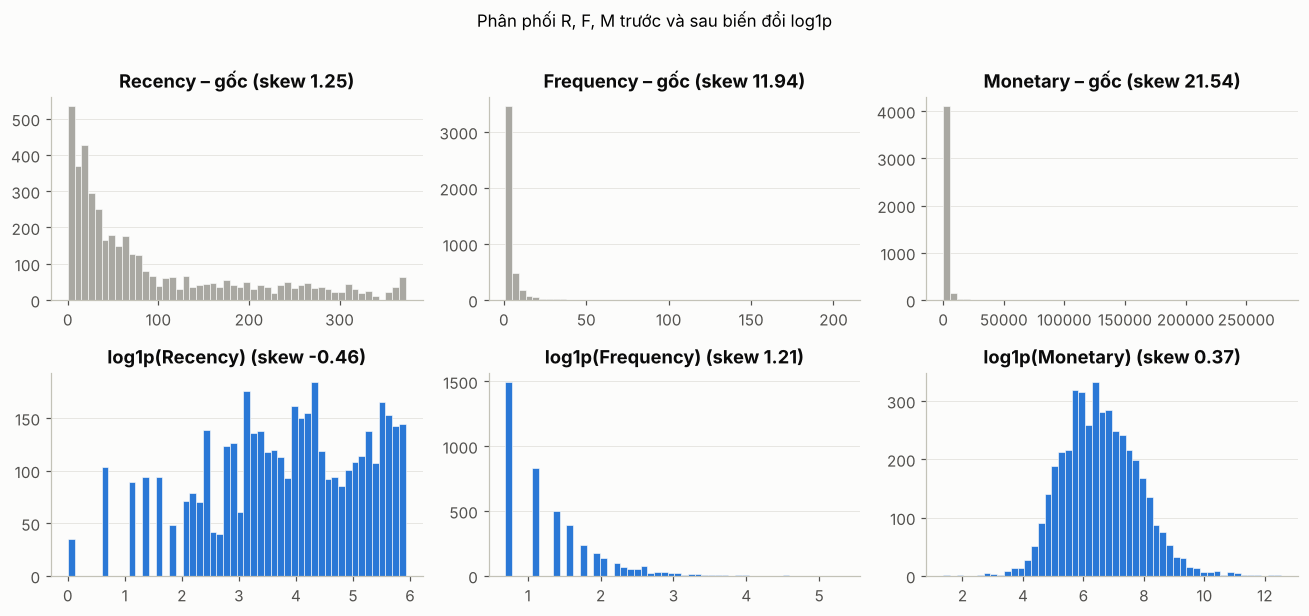

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(12, 5.5))
for j, c in enumerate(CORE):
    axes[0, j].hist(rfm[c], bins=50, color=viz.GREY, edgecolor="#fcfcfb", linewidth=.4)
    axes[0, j].set_title(f"{c} – gốc (skew {rfm[c].skew():.2f})")
    lg = np.log1p(rfm[c])
    axes[1, j].hist(lg, bins=50, color=viz.MAIN, edgecolor="#fcfcfb", linewidth=.4)
    axes[1, j].set_title(f"log1p({c}) (skew {lg.skew():.2f})")
    for ax in axes[:, j]: ax.grid(axis="x", visible=False)
fig.suptitle("Phân phối R, F, M trước và sau biến đổi log1p", y=1.01, fontsize=11)
fig.tight_layout(); viz.save(fig, "fig11_rfm_log_transform"); plt.show()

**Nhận xét:**
- **log1p** giảm mạnh độ lệch: Frequency từ 11,94 xuống 1,21 và Monetary từ 21,54 xuống 0,37. log1p(Monetary) có dạng gần chuẩn. Recency đổi thành lệch trái nhẹ (−0,46), vẫn chấp nhận được.
- **Yeo-Johnson** cho kết quả cân đối hơn (|skew| ≤ 0,22 với R, F, M), nhưng tham số λ khó giải thích bằng ngôn ngữ nghiệp vụ.
- log1p(Frequency) vẫn có dạng rời rạc (các "cột" 1, 2, 3… hóa đơn) do bản chất là biến đếm. Đây là đặc điểm vốn có của dữ liệu và cần lưu ý khi đọc kết quả phân cụm.
- Riêng Tenure: log1p làm phân phối lệch trái mạnh hơn (−0,37 thành −1,60), còn ReturnRate vẫn rất lệch với mọi biến đổi.

## 6. Chuẩn hóa và tạo ma trận đầu vào cho mô hình
- **Bộ RFM chính (3 chiều):** log1p, sau đó StandardScaler. log1p được chọn vì đã đưa skewness của R, F, M về mức chấp nhận được (|skew| ≤ 1,2), đồng thời dễ giải thích và dễ đảo ngược khi diễn giải tâm cụm.
- **Bộ RFM mở rộng (6 chiều):** Yeo-Johnson (đã bao gồm chuẩn hóa), vì log1p làm Tenure lệch trái mạnh (−1,60). ReturnRate không đưa vào mô hình do 65% khách có giá trị 0 nên không biến đổi nào làm phân phối cân đối được; nhóm chỉ dùng nó để mô tả hồ sơ cụm.

Với bộ chính, sau khi biến đổi log1p, nhóm áp dụng **StandardScaler** (z-score: $z = (x - \mu)/\sigma$) để ba chiều R, F, M có cùng thang đo (trung bình 0, độ lệch chuẩn 1). Nếu không chuẩn hóa, chiều Monetary (đơn vị £, giá trị đến hàng trăm nghìn) sẽ áp đảo khoảng cách Euclid.

Ngoại lệ **không bị loại bỏ**: sau log1p, các điểm cực trị đã được "kéo" về gần phần còn lại. Đây cũng là những khách hàng giá trị nhất nên cần được phân khúc. Ở các notebook sau, HDBSCAN có thể nhận diện chúng là nhiễu; độ nhạy của K-Means với các điểm này sẽ được đánh giá trong phần thực nghiệm.

In [13]:
log_core = np.log1p(rfm[CORE])
scaler = StandardScaler()
X_core = pd.DataFrame(scaler.fit_transform(log_core), columns=[f"{c}_s" for c in CORE], index=rfm.index)

# Bộ mở rộng: Yeo-Johnson (+ chuẩn hóa) vì log1p làm Tenure lệch trái mạnh; ReturnRate chỉ dùng để mô tả cụm
EXT_MODEL = ["Recency", "Frequency", "Monetary", "Tenure", "AOV", "NumProducts"]
X_ext = pd.DataFrame(PowerTransformer(method="yeo-johnson").fit_transform(rfm[EXT_MODEL]),
                     columns=[f"{c}_s" for c in EXT_MODEL], index=rfm.index)

display(X_core.describe().T[["mean", "std", "min", "max"]])
print("Kích thước ma trận RFM (3 chiều):", X_core.shape, "| RFM mở rộng (6 chiều):", X_ext.shape)

,mean,std,min,max
Recency_s,0.00,1.00,-2.75,1.53
Frequency_s,0.00,1.00,-0.95,5.85
Monetary_s,-0.00,1.00,-4.16,4.79


Kích thước ma trận RFM (3 chiều): (4320, 3) | RFM mở rộng (6 chiều): (4320, 6)


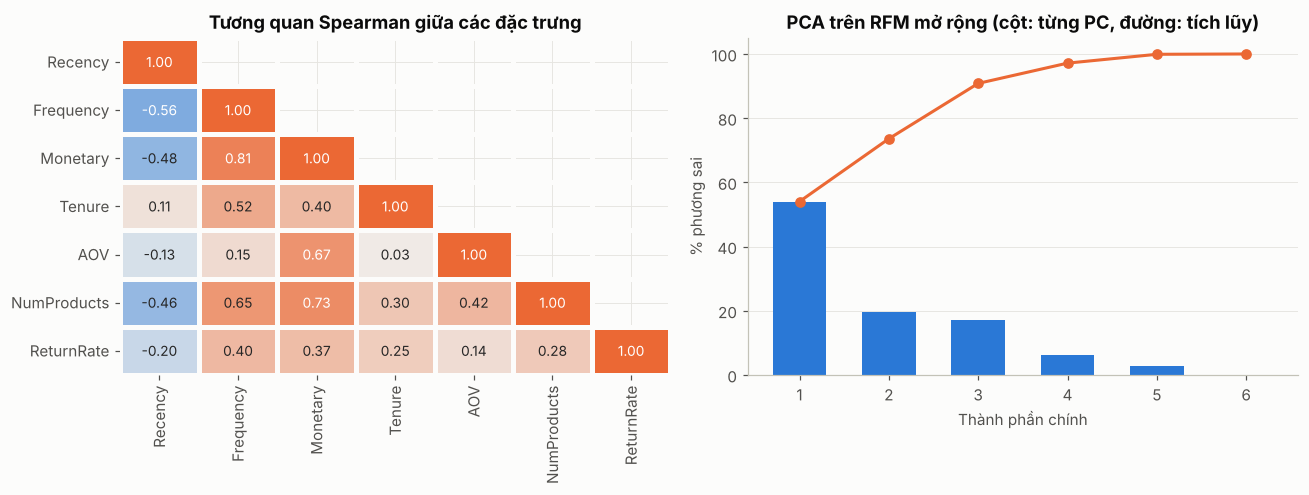

Phương sai tích lũy 2 PC đầu (RFM mở rộng): 73.6%
Phương sai tích lũy 2 PC đầu (RFM 3 chiều): 93.9%


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
corr_raw = rfm[EXT].corr(method="spearman")
mask = np.triu(np.ones_like(corr_raw, dtype=bool), k=1)
sns.heatmap(corr_raw, mask=mask, annot=True, fmt=".2f", cmap=viz.DIV_CMAP, vmin=-1, vmax=1, ax=axes[0],
            cbar=False, linewidths=2, linecolor="#fcfcfb", annot_kws={"size": 9})
axes[0].set_title("Tương quan Spearman giữa các đặc trưng")
pca_full = PCA().fit(X_ext)
ev = pca_full.explained_variance_ratio_
axes[1].bar(range(1, len(ev) + 1), ev * 100, color=viz.MAIN, width=.6)
axes[1].plot(range(1, len(ev) + 1), np.cumsum(ev) * 100, color=viz.ACCENT, marker="o", markersize=6)
axes[1].set_xlabel("Thành phần chính"); axes[1].set_ylabel("% phương sai")
axes[1].set_title("PCA trên RFM mở rộng (cột: từng PC, đường: tích lũy)")
axes[1].grid(axis="x", visible=False)
fig.tight_layout(); viz.save(fig, "fig12_feature_corr_pca"); plt.show()
print("Phương sai tích lũy 2 PC đầu (RFM mở rộng):", f"{np.cumsum(ev)[1]*100:.1f}%")
print("Phương sai tích lũy 2 PC đầu (RFM 3 chiều):", f"{np.cumsum(PCA().fit(X_core).explained_variance_ratio_)[1]*100:.1f}%")

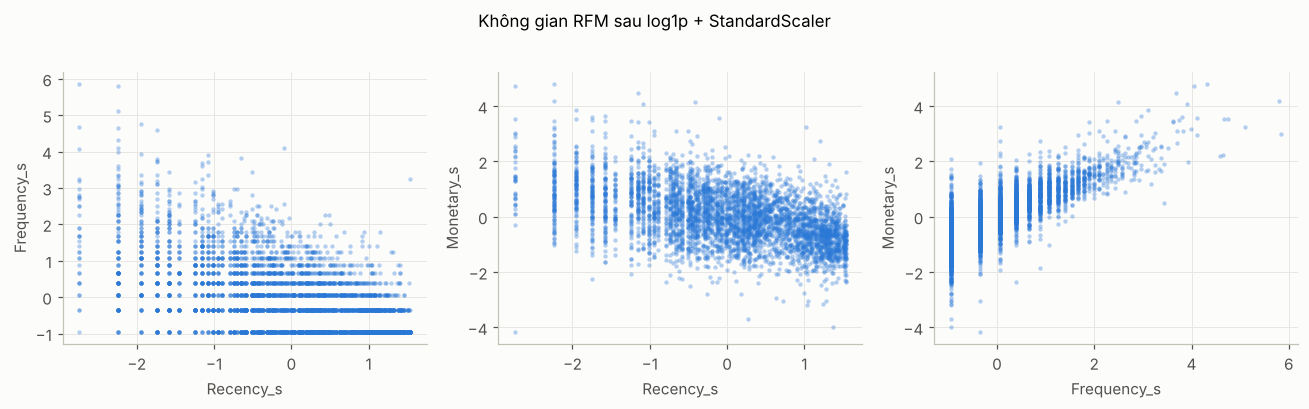

In [15]:
# Trực quan sơ bộ không gian RFM đã chuẩn hóa (chưa phân cụm)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
pairs = [("Recency_s", "Frequency_s"), ("Recency_s", "Monetary_s"), ("Frequency_s", "Monetary_s")]
for ax, (a, b) in zip(axes, pairs):
    ax.scatter(X_core[a], X_core[b], s=8, alpha=.35, color=viz.MAIN, linewidths=0)
    ax.set_xlabel(a); ax.set_ylabel(b)
fig.suptitle("Không gian RFM sau log1p + StandardScaler", y=1.02, fontsize=11)
fig.tight_layout(); viz.save(fig, "fig13_rfm_scaled_scatter"); plt.show()

**Nhận xét:**
- Sau chuẩn hóa, ba chiều R, F, M đều có trung bình 0 và độ lệch chuẩn 1, nên đóng góp cân bằng vào khoảng cách.
- **Tương quan Spearman:** Frequency, Monetary và NumProducts tương quan mạnh với nhau (0,65–0,81). Các đặc trưng mở rộng có phần thông tin trùng lặp với RFM, và đây là lý do nhóm dùng RFM 3 chiều làm đầu vào chính. AOV gần như độc lập với Frequency (0,15), tức là "mua nhiều lần" và "mua đơn lớn" là hai hành vi khác nhau.
- **PCA:** với RFM 3 chiều, 2 thành phần chính giữ được **93,9% phương sai**, nên có thể dùng PCA 2D để trực quan hóa cụm mà ít mất thông tin. Với bộ mở rộng 6 chiều, con số này là 73,6%.
- **Biểu đồ phân tán:** không có các "đám" tách biệt rõ ràng; dữ liệu là một dải liên tục với mật độ thay đổi. Đây là dấu hiệu cho thấy (1) chỉ số Silhouette nhiều khả năng ở mức trung bình (~0,3–0,4); (2) các thuật toán dựa trên mật độ như HDBSCAN có thể gán nhiều điểm là nhiễu. Đây là những giả thuyết sẽ được kiểm chứng ở phần thực nghiệm.

## 7. Baseline: chấm điểm RFM theo quy tắc nghiệp vụ
Đây là cách phân khúc truyền thống trong marketing, không dùng học máy:
1. Chia mỗi chiều R, F, M thành 5 nhóm theo ngũ phân vị và cho điểm 1–5. Với R, giá trị càng nhỏ càng tốt nên điểm đảo ngược. Với F, do có nhiều giá trị trùng (1/3 khách chỉ mua 1 lần), nhóm xếp hạng trước rồi mới chia.
2. Gán phân khúc dựa trên điểm R và điểm trung bình (F+M)/2:

| Phân khúc | Điều kiện |
|---|---|
| Champions | R ≥ 4 và FM ≥ 4 |
| Loyal Customers | R ≥ 3 và FM ≥ 3 |
| New / Promising | R ≥ 4 và FM < 3 |
| Need Attention | R = 3 và FM < 3 |
| At Risk | R ≤ 2 và FM ≥ 3 |
| Hibernating | R = 2 và FM < 3 |
| Lost | R = 1 và FM < 3 |

Kết quả phân khúc này sẽ được dùng làm **mốc so sánh** với các thuật toán phân cụm (độ tương đồng đo bằng ARI/NMI, và khả năng diễn giải).

In [16]:
scores = rfm_scores(rfm)
order = ["Champions", "Loyal Customers", "New / Promising", "Need Attention", "At Risk", "Hibernating", "Lost"]
seg = (scores.join(rfm[["Monetary"]], rsuffix="_")
       .groupby("Segment_Rule")
       .agg(Số_khách=("R", "size"), Recency_TB=("Recency", "mean"), Frequency_TB=("Frequency", "mean"),
            Monetary_TB=("Monetary", "mean"), Tổng_Monetary=("Monetary", "sum"))
       .reindex(order))
seg["% khách"] = 100 * seg["Số_khách"] / seg["Số_khách"].sum()
seg["% doanh thu"] = 100 * seg["Tổng_Monetary"] / seg["Tổng_Monetary"].sum()
seg

,Số_khách,Recency_TB,Frequency_TB,Monetary_TB,Tổng_Monetary,% khách,% doanh thu
Segment_Rule,,,,,,,
Champions,974,12.30,10.92,"5,738.22","5,589,029.74",22.55,67.58
Loyal Customers,835,35.04,3.91,"1,473.78","1,230,604.94",19.33,14.88
New / Promising,405,16.93,1.47,312.96,"126,750.62",9.38,1.53
Need Attention,390,51.72,1.31,342.26,"133,483.32",9.03,1.61
At Risk,528,143.27,3.59,"1,540.58","813,423.69",12.22,9.84
Hibernating,464,119.39,1.35,353.66,"164,099.84",10.74,1.98
Lost,724,274.10,1.17,293.16,"212,245.17",16.76,2.57


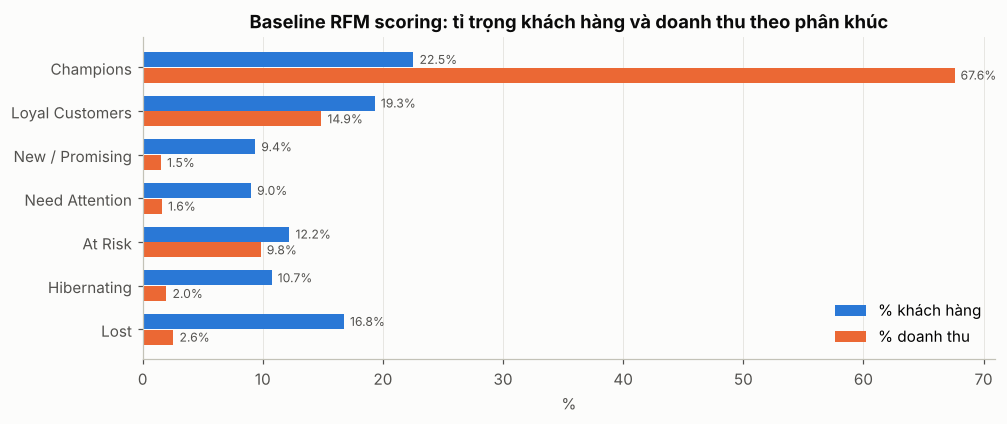

In [17]:
fig, ax = plt.subplots(figsize=(10, 3.8))
y = np.arange(len(order))[::-1]
ax.barh(y + .18, seg["% khách"], height=.34, color=viz.MAIN, label="% khách hàng")
ax.barh(y - .18, seg["% doanh thu"], height=.34, color=viz.ACCENT, label="% doanh thu")
for yi, a, b in zip(y, seg["% khách"], seg["% doanh thu"]):
    ax.text(a + .5, yi + .18, f"{a:.1f}%", va="center", fontsize=8, color=viz.INK2)
    ax.text(b + .5, yi - .18, f"{b:.1f}%", va="center", fontsize=8, color=viz.INK2)
ax.set_yticks(y); ax.set_yticklabels(order); ax.grid(axis="y", visible=False)
ax.legend(loc="lower right"); ax.set_xlabel("%")
ax.set_title("Baseline RFM scoring: tỉ trọng khách hàng và doanh thu theo phân khúc")
viz.save(fig, "fig14_rfm_rule_segments"); plt.show()

**Nhận xét:**
- Baseline theo quy tắc chia 4.320 khách thành 7 phân khúc dễ hiểu. Nhóm **Champions** chiếm 22,5% số khách nhưng tạo ra **67,6% doanh thu**, phù hợp với đường cong Pareto ở EDA.
- Nhóm **At Risk** (12,2% khách, 9,8% doanh thu) là những khách từng mua nhiều nhưng đã khoảng 143 ngày không quay lại: đây là đối tượng ưu tiên cho các chiến dịch giữ chân. Nhóm **Lost** chiếm 16,8% số khách nhưng chỉ 2,6% doanh thu.
- **Hạn chế của baseline:** các ngưỡng (ngũ phân vị) và quy tắc gán nhóm là **chủ quan**; ranh giới cứng giữa các nhóm không phản ánh cấu trúc tự nhiên của dữ liệu; và việc mở rộng thêm đặc trưng (Tenure, AOV…) rất khó. Đây chính là động lực để áp dụng các thuật toán phân cụm, vốn tự học cấu trúc nhóm từ dữ liệu.

## 8. Lưu kết quả cho các notebook phân cụm

In [18]:
sales.to_parquet(OUT / "clean_transactions.parquet", index=False)
rfm.to_csv(OUT / "rfm_features.csv")                                 # đặc trưng gốc (để diễn giải)
X_core.to_csv(OUT / "rfm_model_input.csv")                           # RFM 3 chiều: log1p + z-score
X_ext.to_csv(OUT / "rfm_ext_input.csv")                              # RFM mở rộng 6 chiều: Yeo-Johnson
scores.to_csv(OUT / "rfm_scores.csv")                                # baseline theo quy tắc
for f in sorted(OUT.iterdir()):
    print(f"{f.name:32s} {f.stat().st_size/1024:8.1f} KB")

clean_transactions.parquet         2975.3 KB
cleaning_log.csv                      0.4 KB
rfm_ext_input.csv                   521.8 KB
rfm_features.csv                    308.7 KB
rfm_model_input.csv                 273.2 KB
rfm_scores.csv                      167.6 KB


### Tổng kết notebook 02
- Dữ liệu sau làm sạch và các đặc trưng đã lưu sẵn trong `outputs/`. Notebook 03 (thuật toán phân cụm cổ điển) và 04 (thuật toán hiện đại) chỉ cần đọc `rfm_model_input.csv` (và `rfm_ext_input.csv` cho thử nghiệm mở rộng).
- Đầu vào chính: 3 cột `Recency_s, Frequency_s, Monetary_s`. Đầu vào thử nghiệm mở rộng: 6 cột `*_s` (R, F, M, Tenure, AOV, NumProducts – Yeo-Johnson + chuẩn hóa).
- Baseline để so sánh: cột `Segment_Rule` trong `rfm_scores.csv`.